In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
import warnings

warnings.filterwarnings('ignore')
sns.set(style="whitegrid")

# Incarcarea datelor
train_df = pd.read_csv('CB_OUALD_train.csv')
test_df = pd.read_csv('CB_OUALD_test.csv')

print(f"Set de date incarcat: {train_df.shape[0]} instante de antrenare.")

Set de date incarcat: 18802 instante de antrenare.


Atribute numerice identificate: ['num_of_prev_attempts', 'studied_credits', 'date_registration', 'date_unregistration', 'module_presentation_length', 'n_assessments_early', 'mean_score_early', 'weighted_mean_score_early', 'total_clicks_early', 'active_days_early', 'clicks_dataplus', 'clicks_dualpane', 'clicks_externalquiz', 'clicks_forumng', 'clicks_glossary', 'clicks_homepage', 'clicks_htmlactivity', 'clicks_oucollaborate', 'clicks_oucontent', 'clicks_ouelluminate', 'clicks_ouwiki', 'clicks_page', 'clicks_questionnaire', 'clicks_quiz', 'clicks_repeatactivity', 'clicks_resource', 'clicks_sharedsubpage', 'clicks_subpage', 'clicks_url', 'submission_rate_early', 'refs_oucontent', 'macro_stats']
Atribute categoriale identificate: ['code_module', 'code_presentation', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability', 'clicks_freq_init']


1. Tabel statistici pentru atributele numerice continue:


,Nr_valori_prezente,Medie,Deviatie_Standard,Minim,Percentila_25,Mediana_50,Percentila_75,Maxim
num_of_prev_attempts,18802.0,0.167323,0.479770,0.000000,0.000000,0.000000,0.000000,6.000000
studied_credits,18802.0,80.438517,37.059208,30.000000,60.000000,60.000000,120.000000,430.000000
date_registration,18799.0,-67.866163,47.851521,-311.000000,-98.000000,-54.000000,-29.000000,167.000000
date_unregistration,3542.0,111.385940,62.186144,-196.000000,59.000000,108.000000,159.000000,444.000000
module_presentation_length,18802.0,256.028667,13.326254,234.000000,241.000000,262.000000,268.000000,269.000000
n_assessments_early,18787.0,2.655826,1.149956,1.000000,2.000000,2.000000,3.000000,6.000000
mean_score_early,18770.0,74.364529,17.155703,0.000000,66.500000,78.333333,86.666667,100.000000
weighted_mean_score_early,18780.0,73.426873,16.570319,0.000000,64.697674,76.000000,85.625000,100.000000
total_clicks_early,18802.0,791.462557,860.590991,0.000000,262.000000,523.000000,1004.750000,12783.000000
active_days_early,18802.0,35.612382,22.453023,0.000000,18.000000,31.000000,49.000000,115.000000


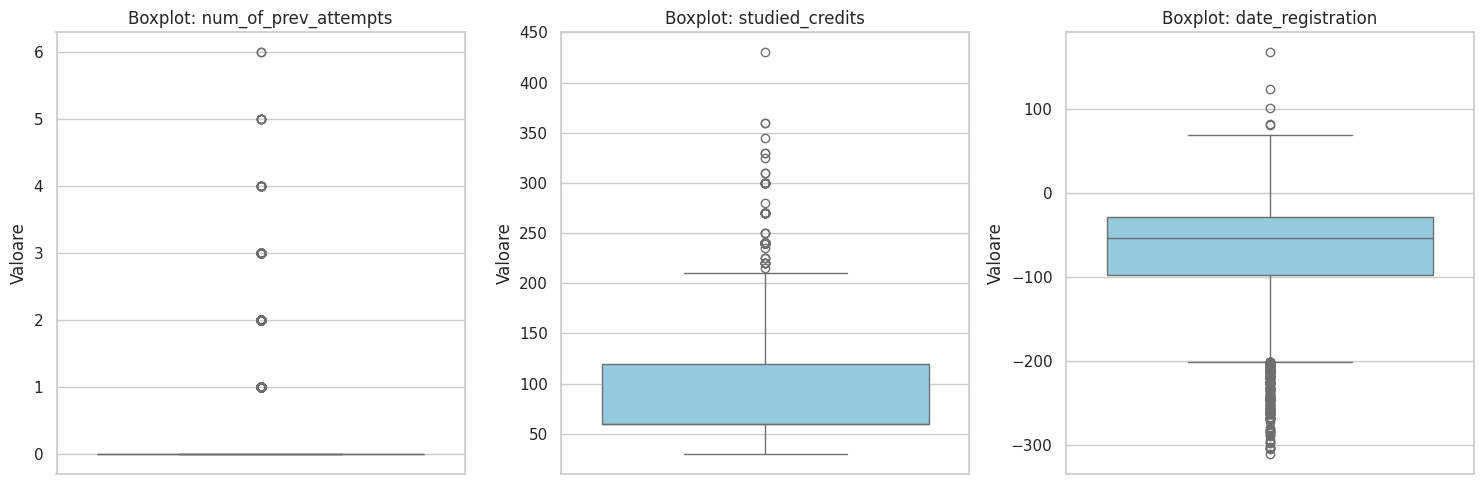



2. Tabel statistici pentru atributele categoriale / ordinale:


,Nr_valori_prezente,Nr_valori_unice
Atribut,,
code_module,18802,6
code_presentation,18802,4
gender,18802,2
region,18802,13
highest_education,18802,5
imd_band,18028,10
age_band,18802,3
disability,18802,2
clicks_freq_init,18742,3


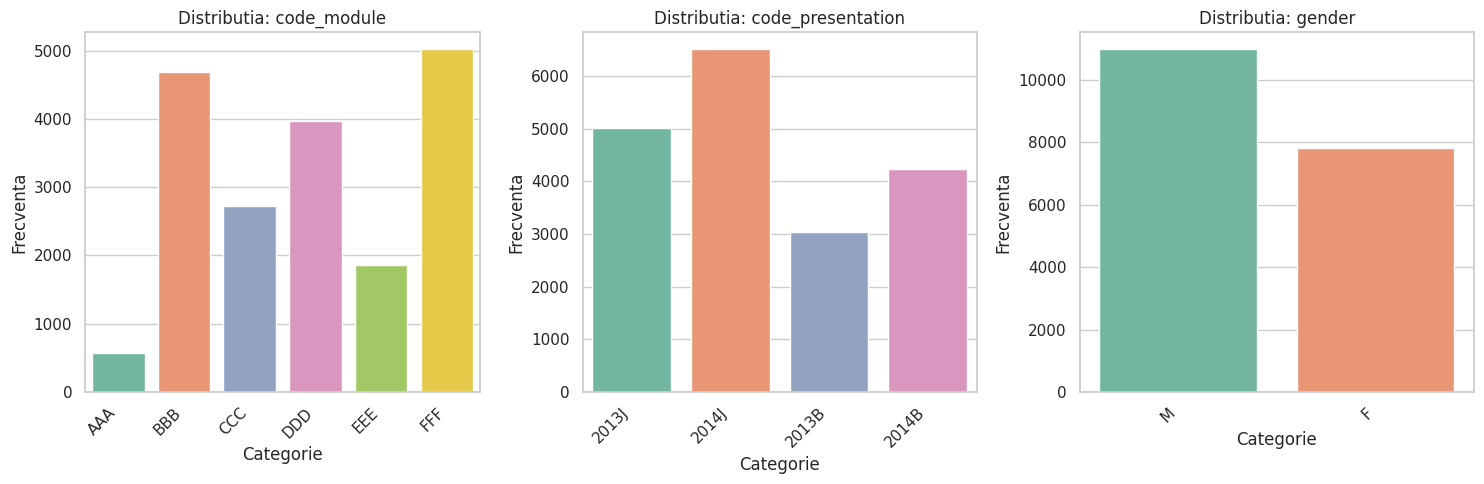

In [10]:
# Identific atributele numerice si cele categoriale
# Scot coloanele tinta ca sa nu le amestec in features
target_cols = ['final_result', 'final_coursework_score']
numeric_cols = [col for col in train_df.select_dtypes(include=[np.number]).columns if col not in target_cols]
categorical_cols = [col for col in train_df.select_dtypes(exclude=[np.number]).columns if col not in target_cols]

print(f"Atribute numerice identificate: {numeric_cols}")
print(f"Atribute categoriale identificate: {categorical_cols}")

print("\n" + "="*50 + "\n")

# Atribute numerice
# Fac tabelul de statistici pentru numerice
# Folosesc describe() si setez percentilele
numeric_stats_df = train_df[numeric_cols].describe(percentiles=[0.25, 0.50, 0.75]).T

# Redenumesc coloanele ca in cerinta
numeric_stats_df = numeric_stats_df.rename(columns={
    'count': 'Nr_valori_prezente',
    'mean': 'Medie',
    'std': 'Deviatie_Standard',
    'min': 'Minim',
    '25%': 'Percentila_25',
    '50%': 'Mediana_50',
    '75%': 'Percentila_75',
    'max': 'Maxim'
})

print("1. Tabel statistici pentru atributele numerice continue:")
display(numeric_stats_df)

# Analizez minim 3 atribute
# Iau primele 3 atribute numerice daca exista
cols_to_plot_num = numeric_cols[:3] if len(numeric_cols) >= 3 else numeric_cols

# Fac boxplot pentru atributele alese
plt.figure(figsize=(15, 5))
for i, col in enumerate(cols_to_plot_num, 1):
    plt.subplot(1, len(cols_to_plot_num), i)
    # Folosesc dropna() ca sa evit erori de la lipsuri
    sns.boxplot(y=train_df[col].dropna(), color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.ylabel('Valoare')

plt.tight_layout()
plt.show()

print("\n" + "="*50 + "\n")

# Atribute discrete / categoriale
# Fac tabelul cerut pentru atributele categoriale
cat_stats = []
for col in categorical_cols:
    # Verific cate valori sunt nenule
    non_null_count = train_df[col].notna().sum()
    # Verific cate categorii unice sunt
    unique_count = train_df[col].nunique()

    cat_stats.append({
        'Atribut': col,
        'Nr_valori_prezente': non_null_count,
        'Nr_valori_unice': unique_count
    })

cat_stats_df = pd.DataFrame(cat_stats).set_index('Atribut')
print("2. Tabel statistici pentru atributele categoriale / ordinale:")
display(cat_stats_df)

# Analizez minim 3 atribute categoriale
cols_to_plot_cat = categorical_cols[:3] if len(categorical_cols) >= 3 else categorical_cols

# Fac histograme ca sa vad distributia categoriilor
plt.figure(figsize=(15, 5))
for i, col in enumerate(cols_to_plot_cat, 1):
    plt.subplot(1, len(cols_to_plot_cat), i)
    # Countplot imi arata frecventa fiecarei categorii
    sns.countplot(data=train_df, x=col, palette='Set2')
    plt.title(f'Distributia: {col}')
    plt.xlabel('Categorie')
    plt.ylabel('Frecventa')
    # Rotesc etichetele daca sunt prea lungi
    plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

Distributia claselor pentru atributul tinta 'final_result':


,Numar de exemple (Suport),Procentaj (%)
final_result,,
Pass,8990,47.81
Fail,4156,22.10
Withdrawn,3554,18.90
Distinction,2102,11.18


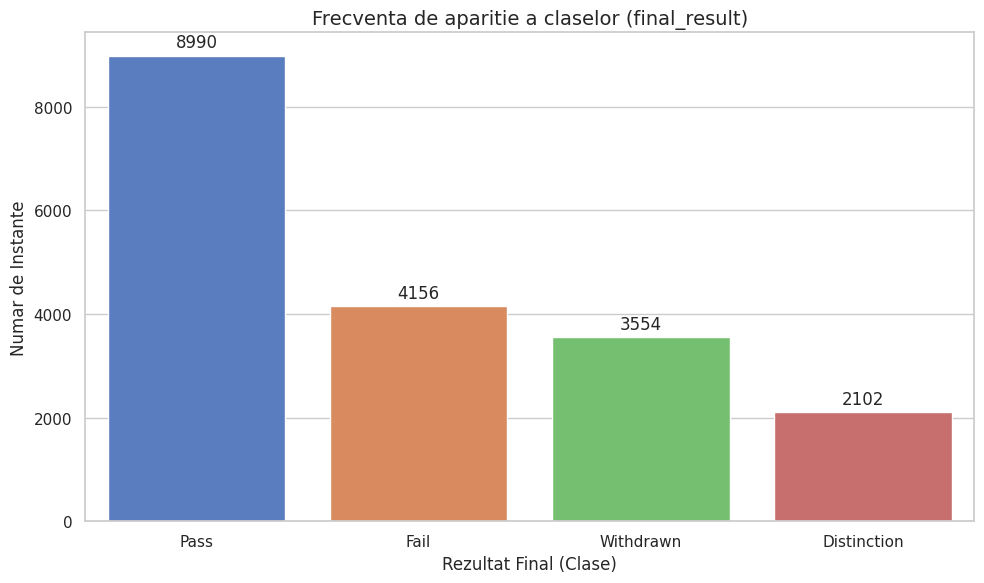

In [11]:
# Verific echilibrul claselor la clasificare
target_col_class = 'final_result'

# Calculez suportul si procentul pe clase
class_counts = train_df[target_col_class].value_counts()
class_percentages = train_df[target_col_class].value_counts(normalize=True) * 100

# Fac un dataframe mic pentru afisare
class_balance_df = pd.DataFrame({
    'Numar de exemple (Suport)': class_counts,
    'Procentaj (%)': class_percentages.round(2)
})

print(f"Distributia claselor pentru atributul tinta '{target_col_class}':")
display(class_balance_df)

# Fac countplot cu seaborn
plt.figure(figsize=(10, 6))

# Salvez axa in 'ax' ca sa pun etichete
ax = sns.countplot(data=train_df, x=target_col_class,
                   # le ordonez de la cea mai frecventa la cea mai rara
                   order=class_counts.index,
                   palette='muted')

plt.title(f'Frecventa de aparitie a claselor ({target_col_class})', fontsize=14)
plt.xlabel('Rezultat Final (Clase)', fontsize=12)
plt.ylabel('Numar de Instante', fontsize=12)

# Pun numarul exact deasupra fiecarei bare
for p in ax.patches:
    height = p.get_height()
    # Textul sta pe mijloc si putin deasupra
    ax.annotate(f'{int(height)}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                # offset 3 pixeli in sus
                xytext=(0, 3),
                textcoords='offset points')

plt.tight_layout()
plt.show()

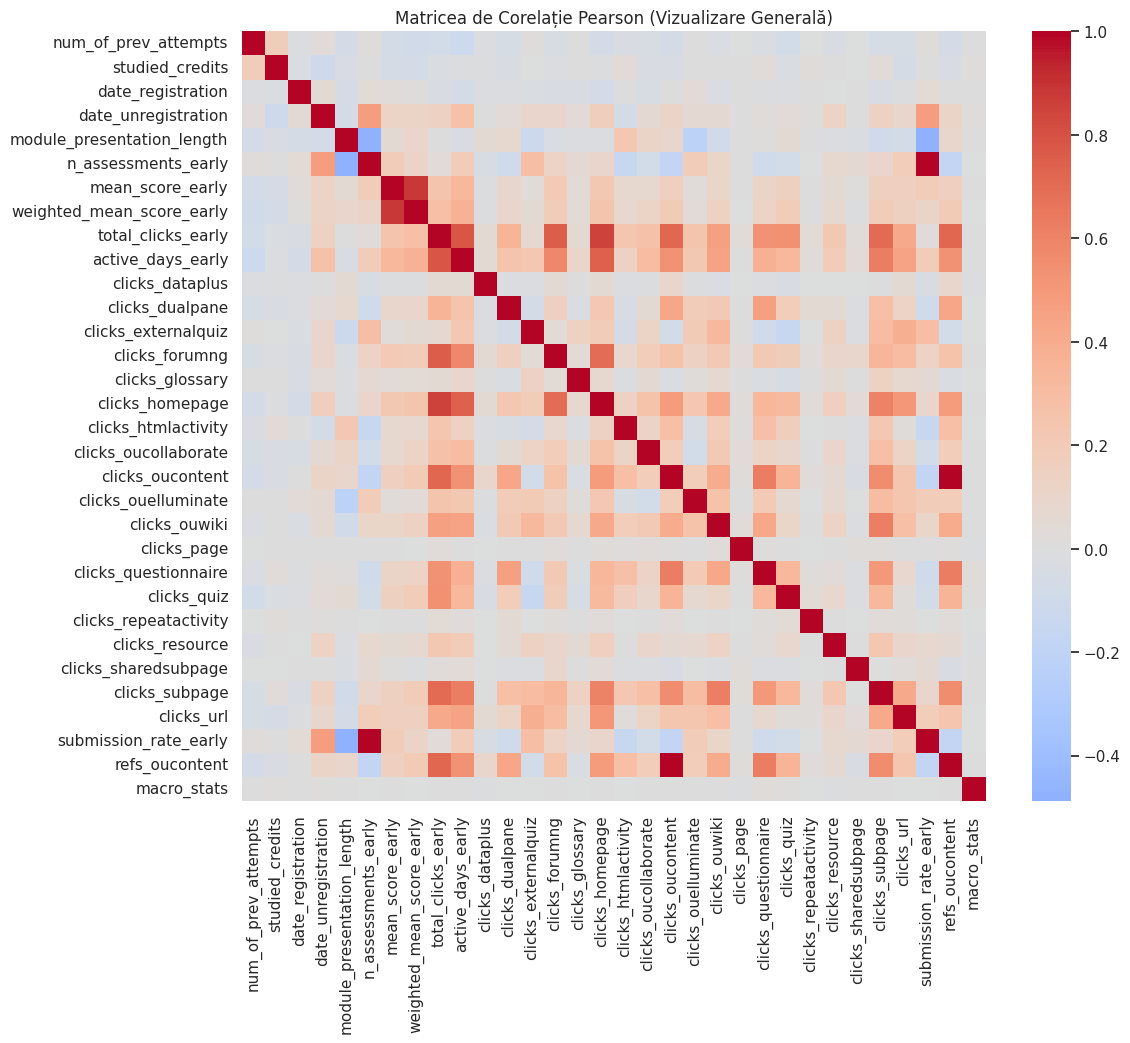

Perechi de atribute potențial redundante (|r| > 0.85):


,,Coeficient Pearson
clicks_oucontent,refs_oucontent,0.999821
weighted_mean_score_early,mean_score_early,0.888106
total_clicks_early,clicks_homepage,0.850937


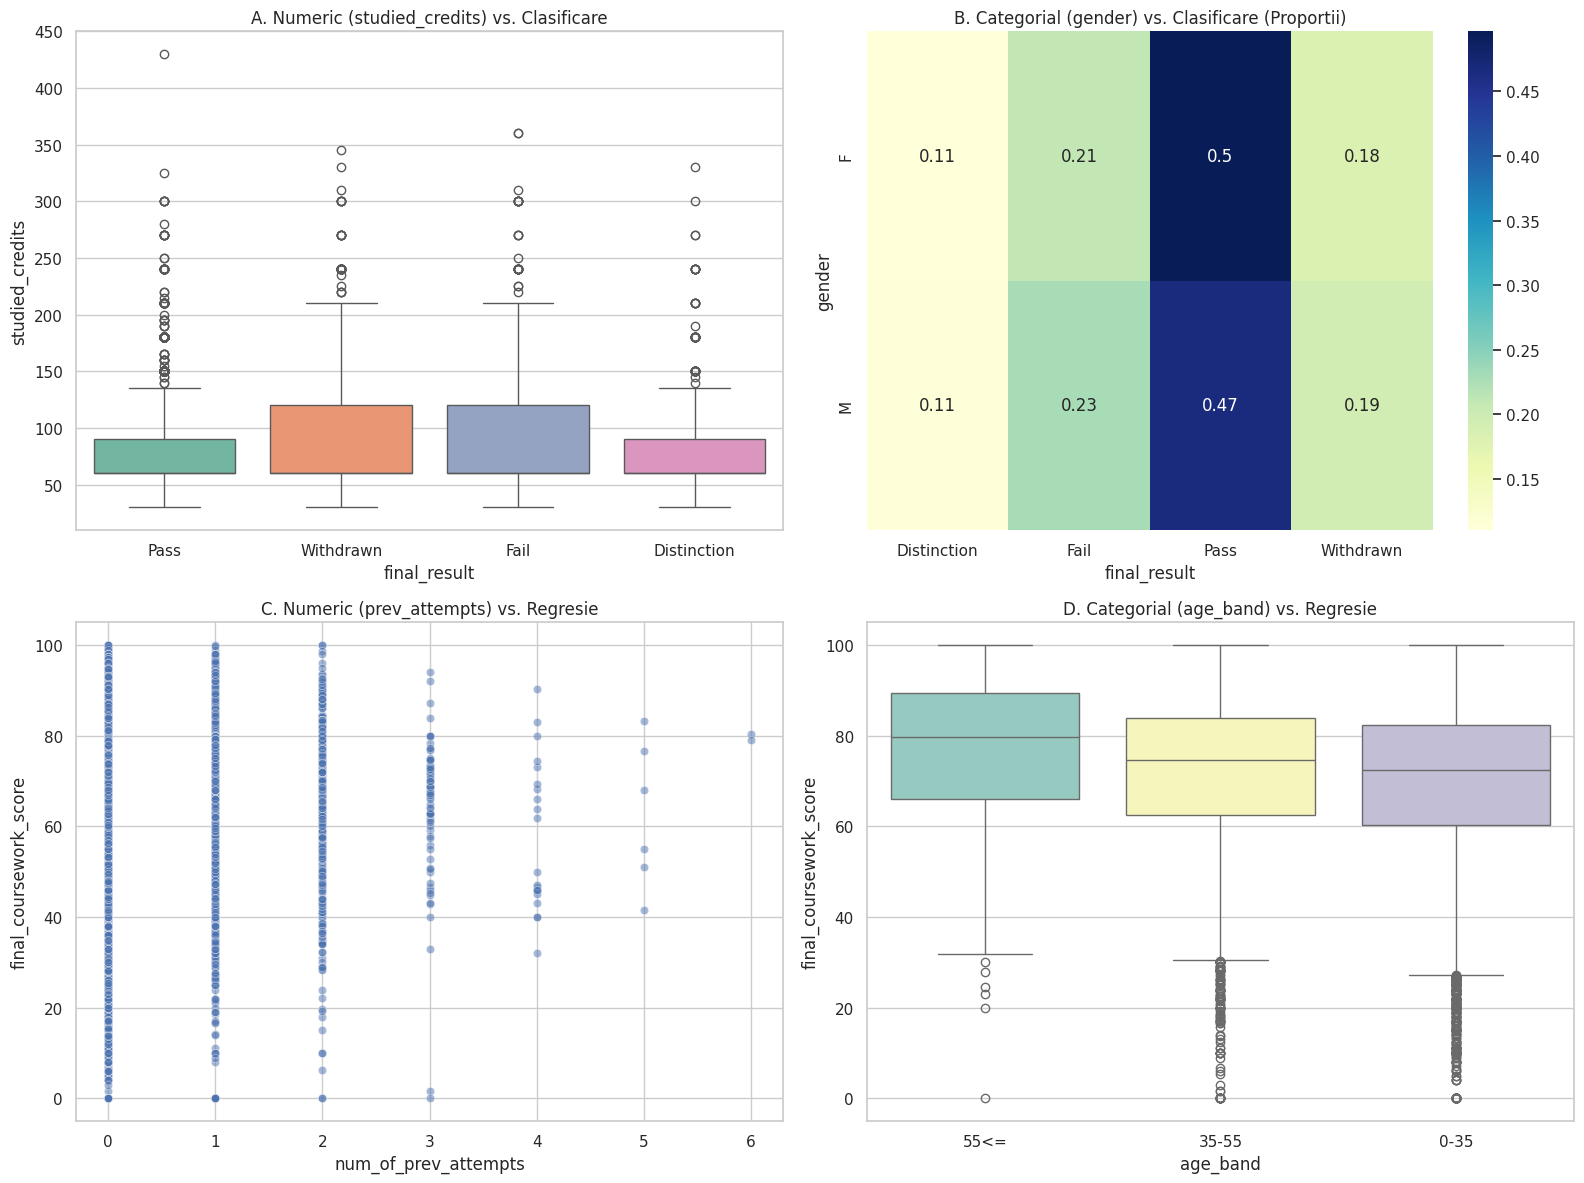

In [12]:
#  Matricea Pearson simplificată (fără numere, doar culori)
plt.figure(figsize=(12, 10))
corr_matrix = train_df[numeric_cols].corr()

# Folosim annot=False pentru a nu supraîncărca graficul
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0)
plt.title('Matricea de Corelație Pearson (Vizualizare Generală)')
plt.show()

# Extragerea perechilor puternic corelate (Redundanță)
# Căutăm corelații mai mari de 0.85 (prag de redundanță)
high_corr = corr_matrix.abs().unstack().sort_values(ascending=False)
high_corr = high_corr[(high_corr > 0.85) & (high_corr < 1.0)]

print("Perechi de atribute potențial redundante (|r| > 0.85):")
if not high_corr.empty:
    display(pd.DataFrame(high_corr, columns=['Coeficient Pearson']).drop_duplicates())
else:
    print("Nu s-au găsit atribute puternic corelate.")


# Analiza pe sarcini de ML
# Fac un grafic compus ca sa bifez tot
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Numeric vs clasificare (final_result)
# Boxplot ca sa vad variatia pe clase
sns.boxplot(ax=axes[0, 0], data=train_df, x='final_result', y='studied_credits', palette='Set2')
axes[0, 0].set_title('A. Numeric (studied_credits) vs. Clasificare')

# Categorial vs clasificare (final_result)
# Heatmap pe tabelul de contingenta
ct_class = pd.crosstab(train_df['gender'], train_df['final_result'], normalize='index')
sns.heatmap(ct_class, annot=True, cmap='YlGnBu', ax=axes[0, 1])
axes[0, 1].set_title('B. Categorial (gender) vs. Clasificare (Proportii)')

# Numeric vs regresie (final_coursework_score)
# Scatter plot ca sa vad relatia liniara
sns.scatterplot(ax=axes[1, 0], data=train_df, x='num_of_prev_attempts', y='final_coursework_score', alpha=0.5)
axes[1, 0].set_title('C. Numeric (prev_attempts) vs. Regresie')

# Categorial vs regresie (final_coursework_score)
# Boxplot pentru notele pe categorii
sns.boxplot(ax=axes[1, 1], data=train_df, x='age_band', y='final_coursework_score', palette='Set3')
axes[1, 1].set_title('D. Categorial (age_band) vs. Regresie')

plt.tight_layout()
plt.show()

In [13]:
# Caut atribute cu date lipsa
missing_values = train_df.isna().sum()
missing_report = missing_values[missing_values > 0].sort_values(ascending=False)

print("Atribute cu valori lipsa si numarul acestora:")
print(missing_report)

# Imputare (cerinta minima)
# Aleg metoda potrivita pe tip de atribut
from sklearn.impute import SimpleImputer

# Imputer numeric cu mediana
# Mediana e mai robusta decat media la outlieri
num_imputer = SimpleImputer(strategy='median')

# Imputer categorial cu moda
cat_imputer = SimpleImputer(strategy='most_frequent')

# Aplic imputarea pe train
# Lucrez separat pe numerice si categoriale
train_df[numeric_cols] = num_imputer.fit_transform(train_df[numeric_cols])
train_df[categorical_cols] = cat_imputer.fit_transform(train_df[categorical_cols])

# Verific daca au ramas lipsuri
print("\nNumar total de valori lipsa dupa imputare:", train_df.isna().sum().sum())

Atribute cu valori lipsa si numarul acestora:
date_unregistration          15260
clicks_resource               5786
clicks_url                    5593
imd_band                       774
clicks_glossary                 60
clicks_homepage                 60
clicks_forumng                  60
clicks_externalquiz             60
clicks_oucollaborate            60
clicks_htmlactivity             60
clicks_dataplus                 60
clicks_dualpane                 60
clicks_subpage                  60
clicks_quiz                     60
clicks_sharedsubpage            60
clicks_repeatactivity           60
clicks_ouwiki                   60
clicks_questionnaire            60
clicks_oucontent                60
clicks_ouelluminate             60
clicks_freq_init                60
refs_oucontent                  60
clicks_page                     57
mean_score_early                32
weighted_mean_score_early       22
n_assessments_early             15
submission_rate_early           15
date_regi

In [14]:
# Aleg o coloana numerica pentru analiza
col_analizata = 'studied_credits'

# Calculez Q1 si Q3
Q1 = train_df[col_analizata].quantile(0.25)
Q3 = train_df[col_analizata].quantile(0.75)

# Calculez IQR
IQR = Q3 - Q1

# Stabilesc pragurile pentru outlieri
limita_inferioara = Q1 - 1.5 * IQR
limita_superioara = Q3 + 1.5 * IQR

# Identific outlierii
outlieri = train_df[(train_df[col_analizata] < limita_inferioara) | (train_df[col_analizata] > limita_superioara)]

print(f"Analiza atributului '{col_analizata}':")
print(f" - Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f" - Praguri: [{limita_inferioara:.2f}, {limita_superioara:.2f}]")
print(f" - Numar de valori extreme detectate: {len(outlieri)}")

# Marchez outlierii ca NaN si ii imput cu mediana
# Conform cerintei ii tratez ca lipsa
train_df.loc[(train_df[col_analizata] < limita_inferioara) | (train_df[col_analizata] > limita_superioara), col_analizata] = np.nan

# Imput cu mediana calculata pe date curate
mediana_curata = train_df[col_analizata].median()
train_df[col_analizata] = train_df[col_analizata].fillna(mediana_curata)

print(f" - Outlierii au fost inlocuiti cu valoarea mediana: {mediana_curata}")

Analiza atributului 'studied_credits':
 - Q1: 60.0, Q3: 120.0, IQR: 60.0
 - Praguri: [-30.00, 210.00]
 - Numar de valori extreme detectate: 153
 - Outlierii au fost inlocuiti cu valoarea mediana: 60.0


In [15]:
# Eliminare atribute redundante (optional)
# Din corelatii identific atribute redundante
# Folosesc lista de atribute gasite
atribute_redundante = ["submission_rate_early", "refs_oucontent"]

# Scot atributele din set daca exista
train_df = train_df.drop(columns=[col for col in atribute_redundante if col in train_df.columns])

print(f"Atribute eliminate pentru reducerea redundantei: {atribute_redundante}")

# Actualizez lista de numerice dupa eliminare
numeric_cols = [col for col in train_df.select_dtypes(include=[np.number]).columns if col not in target_cols]

# Standardizare atribute numerice
from sklearn.preprocessing import StandardScaler

# Initializez StandardScaler
# Media devine 0 si deviatia standard 1
scaler = StandardScaler()

# Pastrez media si deviatia pentru documentare
print("\nStatistici inainte de standardizare (exemplu):")
print(train_df[numeric_cols[:2]].agg(['mean', 'std']))

# Aplic standardizarea pe numerice
train_df[numeric_cols] = scaler.fit_transform(train_df[numeric_cols])

print("\nStatistici dupa standardizare (exemplu):")
print(train_df[numeric_cols[:2]].agg(['mean', 'std']).round(4))

Atribute eliminate pentru reducerea redundantei: ['submission_rate_early', 'refs_oucontent']

Statistici inainte de standardizare (exemplu):
      num_of_prev_attempts  studied_credits
mean              0.167323        78.844272
std               0.479770        33.396251

Statistici dupa standardizare (exemplu):
      num_of_prev_attempts  studied_credits
mean                  -0.0              0.0
std                    1.0              1.0


In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Pregatirea datelor (encodare)
# Encodez y cu LabelEncoder
# Clasele devin 0, 1, 2, 3
le = LabelEncoder()
y = le.fit_transform(train_df['final_result'])

# Encodez X cu One-Hot (get_dummies)
# Se creeaza coloane 0/1 pentru fiecare categorie
X = train_df.drop(columns=['final_result', 'final_coursework_score'])
X = pd.get_dummies(X)

# Impart in train/val 80/20 ca sa masor local
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Baseline: Decision Tree (default)
dt_baseline = DecisionTreeClassifier(random_state=42)
dt_baseline.fit(X_train, y_train)
y_pred_base = dt_baseline.predict(X_val)

acc_base = accuracy_score(y_val, y_pred_base)
print(f"Acuratete Baseline (Default): {acc_base:.4f}")

# Ablatie: variem hiperparametri
# Limitez adancimea ca sa evit overfitting
results = []
for depth in [3, 5, 10, 15, 20]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    acc = accuracy_score(y_val, y_pred)
    results.append({"Max_Depth": depth, "Accuracy_Val": acc})

# Pun rezultatele in tabel pentru jurnal
df_experimente = pd.DataFrame(results)
print("\nJurnal de experimente (Variatie max_depth):")
display(df_experimente)

# Evaluare finala: cel mai bun model
# Aleg modelul cu acuratete maxima pe validare
best_depth = df_experimente.loc[df_experimente['Accuracy_Val'].idxmax(), 'Max_Depth']
print(f"\nCel mai bun hiperparametru gasit: max_depth = {best_depth}")

# Generez matricea de confuzie pentru best model
best_model = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
best_model.fit(X_train, y_train)
y_pred_final = best_model.predict(X_val)

print("\nRaport de clasificare detaliat:")
print(classification_report(y_val, y_pred_final, target_names=le.classes_))

Acuratete Baseline (Default): 0.6652

Jurnal de experimente (Variatie max_depth):


,Max_Depth,Accuracy_Val
0,3,0.681468
1,5,0.720553
2,10,0.738367
3,15,0.713108
4,20,0.688115



Cel mai bun hiperparametru gasit: max_depth = 10

Raport de clasificare detaliat:
              precision    recall  f1-score   support

 Distinction       0.64      0.25      0.36       421
        Fail       0.68      0.48      0.56       831
        Pass       0.68      0.87      0.76      1798
   Withdrawn       1.00      0.99      0.99       711

    accuracy                           0.74      3761
   macro avg       0.75      0.65      0.67      3761
weighted avg       0.74      0.74      0.72      3761



Baseline (Linear Regression) - MSE: 49.9876


,Alpha,Train_MSE,Val_MSE
0,0.01,49.518656,49.987606
1,0.10,49.518656,49.987558
2,1.00,49.518666,49.987086
3,10.00,49.519578,49.983471
4,100.00,49.580743,50.004011
5,1000.00,51.658049,51.865454


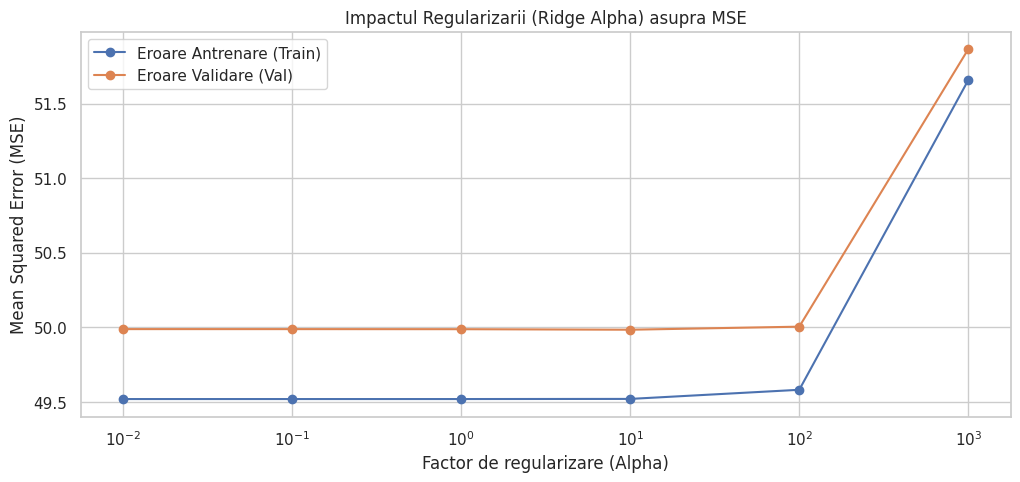

Cel mai bun model: Ridge cu Alpha = 10
MSE Final: 49.9835
MAE Final: 5.0367


In [17]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Pregatirea datelor pentru regresie
# Targetul la regresie e nota finala
y_reg = train_df['final_coursework_score']

# Reutilizez X encodat de la clasificare
# Ma asigur ca nu am randuri fara target
X_reg = X.copy()
# In OUALD targetul e de obicei complet
# Impart datele in train si val
X_train_r, X_val_r, y_train_r, y_val_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Baseline: Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_r, y_train_r)

y_pred_lr = lr_model.predict(X_val_r)
mse_lr = mean_squared_error(y_val_r, y_pred_lr)
print(f"Baseline (Linear Regression) - MSE: {mse_lr:.4f}")

# Regularizare: Ridge Regression
# Variaz alpha
alphas = [0.01, 0.1, 1, 10, 100, 1000]
train_errors = []
val_errors = []

for a in alphas:
    ridge = Ridge(alpha=a)
    ridge.fit(X_train_r, y_train_r)

    # Calculez eroarea pe train si val
    train_errors.append(mean_squared_error(y_train_r, ridge.predict(X_train_r)))
    val_errors.append(mean_squared_error(y_val_r, ridge.predict(X_val_r)))

# Notez rezultatele pentru raport
reg_results_df = pd.DataFrame({
    'Alpha': alphas,
    'Train_MSE': train_errors,
    'Val_MSE': val_errors
})
display(reg_results_df)

# Vizualizare: curbe de eroare
plt.figure(figsize=(12, 5))

# Grafic train vs val ca sa vad overfitting
plt.plot(alphas, train_errors, marker='o', label='Eroare Antrenare (Train)')
plt.plot(alphas, val_errors, marker='o', label='Eroare Validare (Val)')
# scara log pentru a vedea mai bine alpha
plt.xscale('log')
plt.title('Impactul Regularizarii (Ridge Alpha) asupra MSE')
plt.xlabel('Factor de regularizare (Alpha)')
plt.ylabel('Mean Squared Error (MSE)')
plt.legend()
plt.grid(True)
plt.show()

# Evaluare cantitativa finala
best_alpha = alphas[np.argmin(val_errors)]
print(f"Cel mai bun model: Ridge cu Alpha = {best_alpha}")
print(f"MSE Final: {min(val_errors):.4f}")
print(f"MAE Final: {mean_absolute_error(y_val_r, Ridge(alpha=best_alpha).fit(X_train_r, y_train_r).predict(X_val_r)):.4f}")

Tabel Comparativ Clasificare (Masuratori per clasa):


,Algoritm,Accuracy,P_Distinction,R_Distinction,F1_Distinction,P_Fail,R_Fail,F1_Fail,P_Pass,R_Pass,F1_Pass,P_Withdrawn,R_Withdrawn,F1_Withdrawn
0,DT_Baseline (depth=default),0.6652,0.3773,0.3872,0.3822,0.5217,0.5499,0.5354,0.6760,0.6557,0.6657,0.9915,0.9887,0.9901
1,DT_Optimized (max_depth=10),0.7384,0.6364,0.2494,0.3584,0.6844,0.4801,0.5644,0.6805,0.8732,0.7649,0.9958,0.9887,0.9922


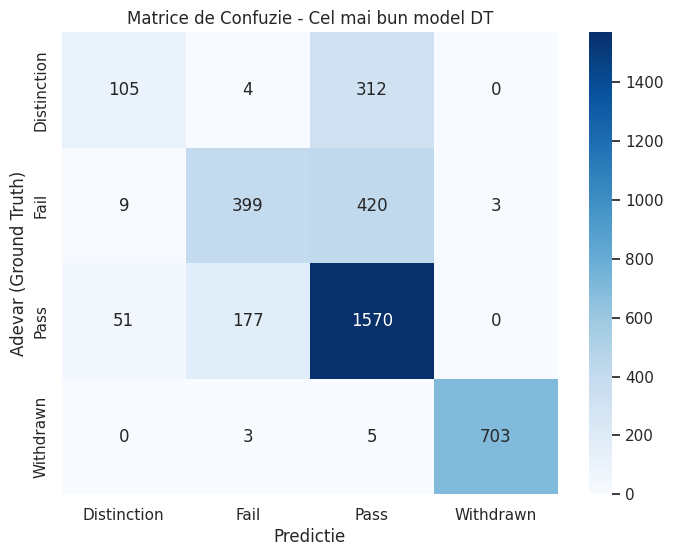

In [18]:
from sklearn.metrics import precision_recall_fscore_support

# Tabel comparativ (cerinta 3.3)
def get_metrics_table(models, X_val, y_val, class_names):
    rows = []
    for name, model in models.items():
        y_pred = model.predict(X_val)
        acc = accuracy_score(y_val, y_pred)

        # Calculez precizie, recall, f1 pe clasa
        p, r, f, _ = precision_recall_fscore_support(y_val, y_pred, labels=range(len(class_names)))

        # Adaug linia cu acuratete si metrici pe clasa
        row = {'Algoritm': name, 'Accuracy': round(acc, 4)}
        for i, class_name in enumerate(class_names):
            row[f'P_{class_name}'] = round(p[i], 4)
            row[f'R_{class_name}'] = round(r[i], 4)
            row[f'F1_{class_name}'] = round(f[i], 4)
        rows.append(row)

    return pd.DataFrame(rows)

# Modele finale in tabel (baseline vs best DT)
final_models_class = {
    'DT_Baseline (depth=default)': dt_baseline,
    # folosesc depth-ul optim gasit anterior
    'DT_Optimized (max_depth=10)': best_model
}

df_class_comp = get_metrics_table(final_models_class, X_val, y_val, le.classes_)

print("Tabel Comparativ Clasificare (Masuratori per clasa):")
# Afisez tabelul
display(df_class_comp)

# Matricea de confuzie (cerinta 3.3)
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_val, y_pred_final)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Matrice de Confuzie - Cel mai bun model DT')
plt.xlabel('Predictie')
plt.ylabel('Adevar (Ground Truth)')
plt.show()

In [19]:
# Tabel comparativ regresie (cerinta 3.3)
def get_regression_metrics(models, X_val, y_val):
    rows = []
    for name, model in models.items():
        y_pred = model.predict(X_val)
        rows.append({
            'Algoritm': name,
            'MAE': round(mean_absolute_error(y_val, y_pred), 4),
            'MSE': round(mean_squared_error(y_val, y_pred), 4),
            'RMSE': round(np.sqrt(mean_squared_error(y_val, y_pred)), 4),
            'R2': round(r2_score(y_val, y_pred), 4)
        })
    return pd.DataFrame(rows)

final_models_reg = {
    'Linear_Regression_Baseline': lr_model,
    'Ridge_Regression (alpha=10)': Ridge(alpha=best_alpha).fit(X_train_r, y_train_r)
}

df_reg_comp = get_regression_metrics(final_models_reg, X_val_r, y_val_r)

print("Tabel Comparativ Regresie:")
display(df_reg_comp)



Tabel Comparativ Regresie:


,Algoritm,MAE,MSE,RMSE,R2
0,Linear_Regression_Baseline,5.0360,49.9876,7.0702,0.818
1,Ridge_Regression (alpha=10),5.0367,49.9835,7.0699,0.818
